# 05 Comparing conduit stats over different caves. 

In [1]:
import numpy as np
import matplotlib.pyplot as plt

from os.path import exists, split, join
from os import makedirs
from tqdm import tqdm
from scipy.stats import gaussian_kde

import base.geometry as geom

from base.utils import list_all_descriptors, return_centreline_parametrisation

Jupyter environment detected. Enabling Open3D WebVisualizer.
[Open3D INFO] WebRTC GUI backend enabled.
[Open3D INFO] WebRTCWindowSystem: HTTP handshake server disabled.


In [2]:
# change here the path to the repository of karst catalogue
data_repository = "F:/ScanLeica/data_paper/KarstConduitCatalogue" 
descriptor_filepaths = list_all_descriptors(data_repository)

In [3]:
descriptor_filepaths

['F:\\ScanLeica\\data_paper\\KarstConduitCatalogue\\Archamps\\PostEtroiture\\geometric_descriptors\\section_descriptors.txt',
 'F:\\ScanLeica\\data_paper\\KarstConduitCatalogue\\Archamps\\PreEtroiture\\geometric_descriptors\\section_descriptors.txt',
 'F:\\ScanLeica\\data_paper\\KarstConduitCatalogue\\BaumeDeLongeaigue\\GrandToboggan\\geometric_descriptors\\section_descriptors.txt',
 'F:\\ScanLeica\\data_paper\\KarstConduitCatalogue\\CascadeDeMotiers\\MainGallery\\geometric_descriptors\\section_descriptors.txt',
 'F:\\ScanLeica\\data_paper\\KarstConduitCatalogue\\CocaliereCotepatiere\\AvenDeLaCocaliere1\\geometric_descriptors\\section_descriptors.txt',
 'F:\\ScanLeica\\data_paper\\KarstConduitCatalogue\\CocaliereCotepatiere\\AvenDeLaCocaliere2\\geometric_descriptors\\section_descriptors.txt',
 'F:\\ScanLeica\\data_paper\\KarstConduitCatalogue\\CocaliereCotepatiere\\AvenDeLaCocaliere3\\geometric_descriptors\\section_descriptors.txt',
 'F:\\ScanLeica\\data_paper\\KarstConduitCatalogue\\C

Now we check the descriptor files which have been generated. 

In [4]:
valid_indices = [c for c, file in enumerate(descriptor_filepaths) if exists(file)]
print(valid_indices)

[0, 1, 2, 3, 4, 5, 6, 7, 8, 9, 10, 11, 12, 13, 14, 15, 16, 17, 18, 19, 20, 21, 22]


In [5]:
with open(descriptor_filepaths[valid_indices[0]], "r") as f:
    header = f.readline()[2:-1].split(",")
    f.close()

In [6]:
all_data = []
for idx in valid_indices:
    data = np.loadtxt(descriptor_filepaths[idx], skiprows=1)

    the_index = np.ones(len(data))*idx
    indexed_data = np.vstack([the_index, data.T])

    all_data.append(indexed_data.T)

all_data = np.vstack(all_data)

In [7]:
len(all_data.T)

22

In [8]:
len(header)

21

In [9]:
header = ["index"]+ header

In [10]:
np.savetxt("./temp/barcelona_figures/all_descriptor_data.txt", all_data, header=" ".join(header))

In [11]:
header

['index',
 'area',
 'ellipse_aspect_ratio',
 'ellipse_rotation',
 'perimeter',
 'solidity',
 'hydraulic_diameter',
 'max_chord_length',
 'rmax',
 'rmin',
 'r_average',
 'circularity',
 'gravelius_compactness',
 'circularity3',
 'deviation_from_inscribed_disk',
 'deviation_from_circumscribed_disk',
 'elongation',
 'isoperimetric_deficiency',
 'morton_spreading_index',
 'circular_variance',
 'is_closed',
 'curvilinear_coord']

In [20]:
def general_boxplot(ax, indexed_data, col, xpos, labels= None, color = "dodgerblue", xoffset = 0, xscale = 0.125):
   
    for thepos in xpos:
        thepos_tick = thepos+ xoffset
        isindex = np.argwhere(indexed_data[:, 0]==thepos).flatten()
        indexed_col_data = indexed_data[isindex, col]

        # scatter the median. 
        quantiles = np.quantile(indexed_col_data, [0.25, 0.5, 0.75, 0.005,0.995])
        iq = quantiles[2] -quantiles[0] 
        high_flyer = min(quantiles[1]+1.5*iq, quantiles[4]) 
        low_flyer = max(quantiles[1]-1.5*iq, quantiles[3])

        extreme_above = np.logical_and(indexed_col_data > high_flyer, indexed_col_data < quantiles[4])
        extreme_below = np.logical_and(indexed_col_data < low_flyer, indexed_col_data > quantiles[3])
        extremes = ((indexed_col_data[extreme_below], indexed_col_data[extreme_above]))


        ax.plot([thepos_tick-0.7*xscale, thepos_tick+0.7*xscale], [quantiles[1], quantiles[1]],lw = 2,  color = color)
        ax.plot([thepos_tick-xscale, thepos_tick+xscale], [quantiles[0], quantiles[0]], color = color)
        ax.plot([thepos_tick-xscale, thepos_tick+xscale], [quantiles[2], quantiles[2]], color = color)

        ax.plot([thepos_tick-0.4*xscale, thepos_tick+0.4*xscale], [low_flyer, low_flyer], color = color)
        ax.plot([thepos_tick-0.4*xscale, thepos_tick+0.4*xscale], [high_flyer, high_flyer], color = color)

        ax.plot([thepos_tick, thepos_tick], [low_flyer, quantiles[0]], color = color)
        ax.plot([thepos_tick, thepos_tick], [high_flyer, quantiles[2]], color = color)

        ax.plot([thepos_tick-xscale, thepos_tick-xscale], [quantiles[0], quantiles[2]], color = color)
        ax.plot([thepos_tick+xscale, thepos_tick+xscale], [quantiles[0], quantiles[2]], color = color)

        ax.scatter(len(extremes[0])* [thepos_tick], extremes[0], s = 1, color = color)
        ax.scatter(len(extremes[1])* [thepos_tick], extremes[1], s = 1, color = color)

        if labels != None:
            ax.set_xticks(xpos)
            ax.set_xticklabels(labels, rotation=90)

In [29]:
def single_boxplot(ax, data, xpos, labels= None, color = "dodgerblue", xoffset = 0, xscale = 0.125):
   
    for thepos in xpos:
        thepos_tick = thepos+ xoffset
        indexed_col_data = data

        # scatter the median. 
        quantiles = np.quantile(indexed_col_data, [0.25, 0.5, 0.75, 0.005,0.995])
        iq = quantiles[2] -quantiles[0] 
        high_flyer = min(quantiles[1]+1.5*iq, quantiles[4]) 
        low_flyer = max(quantiles[1]-1.5*iq, quantiles[3])

        extreme_above = np.logical_and(indexed_col_data > high_flyer, indexed_col_data < quantiles[4])
        extreme_below = np.logical_and(indexed_col_data < low_flyer, indexed_col_data > quantiles[3])
        extremes = ((indexed_col_data[extreme_below], indexed_col_data[extreme_above]))


        ax.plot([thepos_tick-0.7*xscale, thepos_tick+0.7*xscale], [quantiles[1], quantiles[1]],lw = 2,  color = color)
        ax.plot([thepos_tick-xscale, thepos_tick+xscale], [quantiles[0], quantiles[0]], color = color)
        ax.plot([thepos_tick-xscale, thepos_tick+xscale], [quantiles[2], quantiles[2]], color = color)

        ax.plot([thepos_tick-0.4*xscale, thepos_tick+0.4*xscale], [low_flyer, low_flyer], color = color)
        ax.plot([thepos_tick-0.4*xscale, thepos_tick+0.4*xscale], [high_flyer, high_flyer], color = color)

        ax.plot([thepos_tick, thepos_tick], [low_flyer, quantiles[0]], color = color)
        ax.plot([thepos_tick, thepos_tick], [high_flyer, quantiles[2]], color = color)

        ax.plot([thepos_tick-xscale, thepos_tick-xscale], [quantiles[0], quantiles[2]], color = color)
        ax.plot([thepos_tick+xscale, thepos_tick+xscale], [quantiles[0], quantiles[2]], color = color)

        ax.scatter(len(extremes[0])* [thepos_tick], extremes[0], s = 1, color = color)
        ax.scatter(len(extremes[1])* [thepos_tick], extremes[1], s = 1, color = color)

        if labels != None:
            ax.set_xticks(xpos)
            ax.set_xticklabels(labels, rotation=90)

In [43]:
from base.geometry import DESCRIPTOR_MAP

In [48]:
from matplotlib.cm import tab20b


14


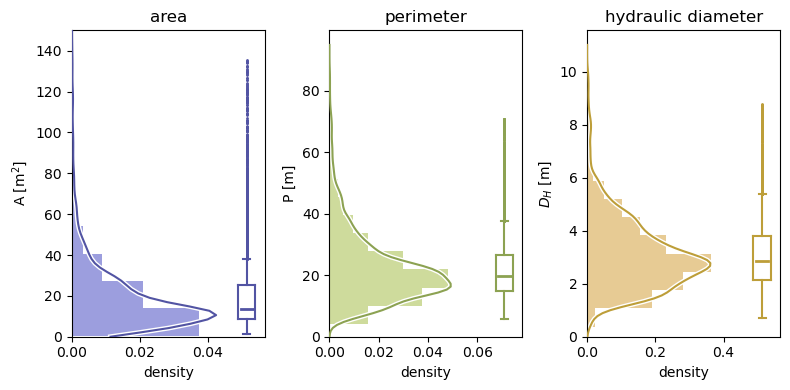

In [65]:
fig, axes = plt.subplots(1,3, figsize=(8, 4))

nbins = int(1+np.log2(len(all_data)))
print(nbins)
k = 0
attrs = (1, 4, 6)
for ax, idx in zip(axes, attrs):
    color = tab20b(4*k+1)
    colorlight = tab20b(4*k+3)
    y = all_data[:, idx]
    _min = np.quantile(y, 0.005)
    _max = np.quantile(y, 0.995)
    within_99 = np.logical_and(y > _min, y < _max)
    _range = _max - _min

    yi = np.linspace(np.maximum(0, _min - 0.1*_range), np.minimum(_max + 0.1*_range, np.max(y)), 100)
    
    kde = gaussian_kde(y[within_99]).evaluate(yi)
    ax.hist(y[within_99],  density = True, bins=14, orientation="horizontal", color = colorlight)
    ax.plot(kde, yi, lw = 3.5,c  = "white", zorder = 2)
    ax.plot(kde, yi, lw = 1.5,c  = color, zorder = 3)
    xpos = np.max(np.histogram(y[within_99], density=True)[0])*1.5
    single_boxplot(ax, y[within_99], xpos = [xpos], xoffset=0, xscale=0.05*xpos, color=color)
    ax.set_xlabel("density")

    # 
    theunit = DESCRIPTOR_MAP[header[idx]]["unit"]
    thelabel = DESCRIPTOR_MAP[header[idx]]["name"]
    theabbr = DESCRIPTOR_MAP[header[idx]]["abbr"]
    n = len(all_data)
    ax.set_title(f"{thelabel}")

    ax.set_ylabel(f"{theabbr} [{theunit}]")
    k+=1
    ax.set_ylim(0, None)

axes[0].set_ylim(0, 150)
plt.tight_layout()
str_attrs = [str(elem) for elem in attrs]
plt.savefig(f"./temp/barcelona_figures/first_order_stats_{'_'.join(str_attrs)}.png")

In [67]:
header

['index',
 'area',
 'ellipse_aspect_ratio',
 'ellipse_rotation',
 'perimeter',
 'solidity',
 'hydraulic_diameter',
 'max_chord_length',
 'rmax',
 'rmin',
 'r_average',
 'circularity',
 'gravelius_compactness',
 'circularity3',
 'deviation_from_inscribed_disk',
 'deviation_from_circumscribed_disk',
 'elongation',
 'isoperimetric_deficiency',
 'morton_spreading_index',
 'circular_variance',
 'is_closed',
 'curvilinear_coord']

14


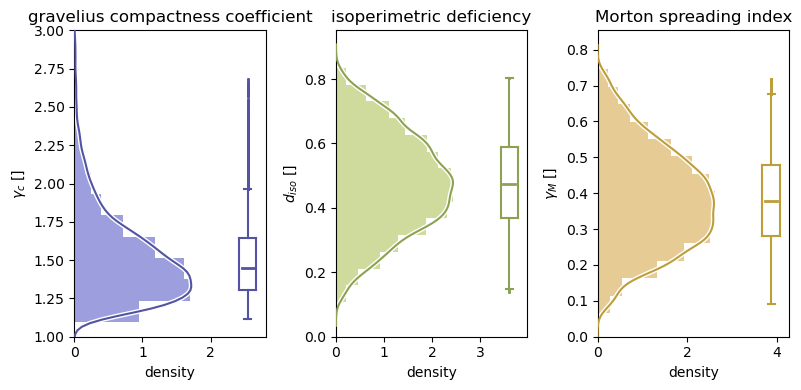

In [ ]:
fig, axes = plt.subplots(1,3, figsize=(8, 4))

nbins = int(1+np.log2(len(all_data)))
print(nbins)
k = 0
attrs = (12, 17, 18)

for ax, idx in zip(axes, attrs):
    color = tab20b(4*k+1)
    colorlight = tab20b(4*k+3)
    y = all_data[:, idx]
    _min = np.quantile(y, 0.005)
    _max = np.quantile(y, 0.995)
    within_99 = np.logical_and(y > _min, y < _max)
    _range = _max - _min

    yi = np.linspace(np.maximum(0, _min - 0.1*_range), np.minimum(_max + 0.1*_range, np.max(y)), 100)
    
    kde = gaussian_kde(y[within_99]).evaluate(yi)
    ax.hist(y[within_99],  density = True, bins=14, orientation="horizontal", color = colorlight)
    ax.plot(kde, yi, lw = 3.5,c  = "white", zorder = 2)
    ax.plot(kde, yi, lw = 1.5,c  = color, zorder = 3)
    xpos = np.max(np.histogram(y[within_99], density=True)[0])*1.5
    single_boxplot(ax, y[within_99], xpos = [xpos], xoffset=0, xscale=0.05*xpos, color=color)
    ax.set_xlabel("density")

    # 
    theunit = DESCRIPTOR_MAP[header[idx]]["unit"]
    thelabel = DESCRIPTOR_MAP[header[idx]]["name"]
    theabbr = DESCRIPTOR_MAP[header[idx]]["abbr"]
    n = len(all_data)
    ax.set_title(f"{thelabel}")

    ax.set_ylabel(f"{theabbr} [{theunit}]")
    k+=1
    ax.set_ylim(0, None)


plt.tight_layout()
str_attrs = [str(elem) for elem in attrs]

axes[0].set_ylim(1, 3) 


plt.savefig(f"./temp/barcelona_figures/first_order_stats_{'_'.join(str_attrs)}.png")

14


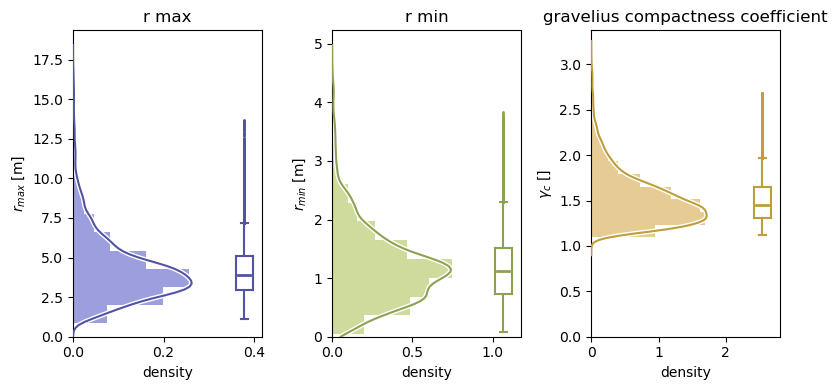

In [66]:
fig, axes = plt.subplots(1,3, figsize=(8, 4))

nbins = int(1+np.log2(len(all_data)))
print(nbins)
k = 0
attrs = (8, 9, 12)

for ax, idx in zip(axes, attrs):
    color = tab20b(4*k+1)
    colorlight = tab20b(4*k+3)
    y = all_data[:, idx]
    _min = np.quantile(y, 0.005)
    _max = np.quantile(y, 0.995)
    within_99 = np.logical_and(y > _min, y < _max)
    _range = _max - _min

    yi = np.linspace(np.maximum(0, _min - 0.1*_range), np.minimum(_max + 0.1*_range, np.max(y)), 100)
    
    kde = gaussian_kde(y[within_99]).evaluate(yi)
    ax.hist(y[within_99],  density = True, bins=14, orientation="horizontal", color = colorlight)
    ax.plot(kde, yi, lw = 3.5,c  = "white", zorder = 2)
    ax.plot(kde, yi, lw = 1.5,c  = color, zorder = 3)
    xpos = np.max(np.histogram(y[within_99], density=True)[0])*1.5
    single_boxplot(ax, y[within_99], xpos = [xpos], xoffset=0, xscale=0.05*xpos, color=color)
    ax.set_xlabel("density")

    # 
    theunit = DESCRIPTOR_MAP[header[idx]]["unit"]
    thelabel = DESCRIPTOR_MAP[header[idx]]["name"]
    theabbr = DESCRIPTOR_MAP[header[idx]]["abbr"]
    n = len(all_data)
    ax.set_title(f"{thelabel}")

    ax.set_ylabel(f"{theabbr} [{theunit}]")
    k+=1
    ax.set_ylim(0, None)


plt.tight_layout()
str_attrs = [str(elem) for elem in attrs]
plt.savefig(f"./temp/barcelona_figures/first_order_stats_{'_'.join(str_attrs)}.png")

(array([1378., 1780., 2401., 1193.,  865.,  798.,  454.,  285.,  237.,
         170.,  101.,   79.,   83.,   46.,   40.,   38.,   26.,   21.,
          22.]),
 array([ 0,  5, 10, 15, 20, 25, 30, 35, 40, 45, 50, 55, 60, 65, 70, 75, 80,
        85, 90, 95]),
 <BarContainer object of 19 artists>)

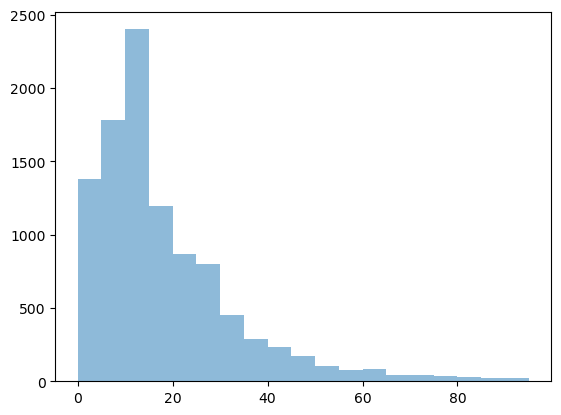

In [13]:
fig, ax = plt.subplots()

ax.hist(all_data[:, 1], bins = np.arange(0, 100,5), alpha = 0.5)

In [14]:
thedescriptor = 1 # for area. 

In [15]:
attr = [0, 3, 5]

In [16]:
nattr = len(attr)

In [17]:
header

['index',
 'area',
 'ellipse_aspect_ratio',
 'ellipse_rotation',
 'perimeter',
 'solidity',
 'hydraulic_diameter',
 'max_chord_length',
 'rmax',
 'rmin',
 'r_average',
 'circularity',
 'gravelius_compactness',
 'circularity3',
 'deviation_from_inscribed_disk',
 'deviation_from_circumscribed_disk',
 'elongation',
 'isoperimetric_deficiency',
 'morton_spreading_index',
 'circular_variance',
 'is_closed',
 'curvilinear_coord']

FileNotFoundError: F:\ScanLeica\data_paper\KarstConduitCatalogue\Archamps\PostEtroiture\geometric_descriptors\sections\ignore_flags.txt not found.

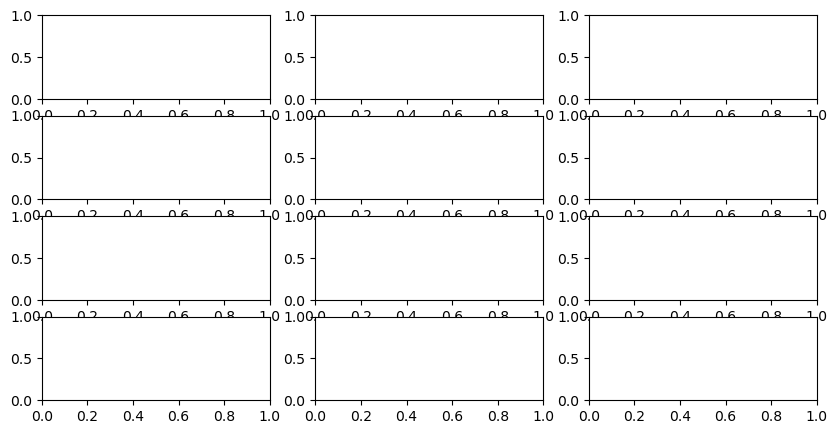

In [18]:
# plot some histograms of the different caves with tab20b. 
fig, axes = plt.subplots(4, nattr, figsize =(10, 5))

for n, idx in enumerate(valid_indices):
    for c, thedescriptor in enumerate(attr):
        thedescriptor+=1
        idx_subset = np.argwhere(all_data[:, 0] == idx).flatten()
        ignore_calc = np.loadtxt(join(split(descriptor_filepaths[idx])[0], "sections", "ignore_flags.txt"))
        descriptor = all_data[idx_subset, thedescriptor][~ignore_calc.astype(bool)]
        nbins = int(np.floor(1 + np.log2(len(descriptor))))

        within_99 = np.argwhere(np.logical_and(descriptor > np.quantile(descriptor, 0.005), descriptor < np.quantile(descriptor, 0.995)))
        descriptor_ok = descriptor[within_99].flatten()
        print(len(descriptor_ok))
        kde = gaussian_kde(descriptor_ok)
        _min, _max = np.min(descriptor_ok), np.max(descriptor_ok)
        xi = np.linspace(_min, _max)
        axes[n, c].hist(descriptor_ok, bins = nbins, color = tab20b(4*n+3), density = True)
        axes[n, c].plot(xi, kde.evaluate(xi), color = tab20b(4*n), zorder = 2)

ranges = [(0, 40), (0, 40), (0, 6)]
for c, therange in enumerate(ranges):
    for ax in axes[:, c]:
        ax.set_xlim(*therange)
plt.tight_layout()
plt.show()

In [ ]:
def general_boxplot(ax, indexed_data, col, xpos, labels= None, color = "dodgerblue", xoffset = 0, xscale = 0.125):
   
    for thepos in xpos:
        thepos_tick = thepos+ xoffset
        isindex = np.argwhere(indexed_data[:, 0]==thepos).flatten()
        indexed_col_data = indexed_data[isindex, col]

        # scatter the median. 
        quantiles = np.quantile(indexed_col_data, [0.25, 0.5, 0.75, 0.005,0.995])
        iq = quantiles[2] -quantiles[0] 
        high_flyer = min(quantiles[1]+1.5*iq, quantiles[4]) 
        low_flyer = max(quantiles[1]-1.5*iq, quantiles[3])

        extreme_above = np.logical_and(indexed_col_data > high_flyer, indexed_col_data < quantiles[4])
        extreme_below = np.logical_and(indexed_col_data < low_flyer, indexed_col_data > quantiles[3])
        extremes = ((indexed_col_data[extreme_below], indexed_col_data[extreme_above]))


        ax.plot([thepos_tick-0.7*xscale, thepos_tick+0.7*xscale], [quantiles[1], quantiles[1]],lw = 2,  color = color)
        ax.plot([thepos_tick-xscale, thepos_tick+xscale], [quantiles[0], quantiles[0]], color = color)
        ax.plot([thepos_tick-xscale, thepos_tick+xscale], [quantiles[2], quantiles[2]], color = color)

        ax.plot([thepos_tick-0.4*xscale, thepos_tick+0.4*xscale], [low_flyer, low_flyer], color = color)
        ax.plot([thepos_tick-0.4*xscale, thepos_tick+0.4*xscale], [high_flyer, high_flyer], color = color)

        ax.plot([thepos_tick, thepos_tick], [low_flyer, quantiles[0]], color = color)
        ax.plot([thepos_tick, thepos_tick], [high_flyer, quantiles[2]], color = color)

        ax.plot([thepos_tick-xscale, thepos_tick-xscale], [quantiles[0], quantiles[2]], color = color)
        ax.plot([thepos_tick+xscale, thepos_tick+xscale], [quantiles[0], quantiles[2]], color = color)

        ax.scatter(len(extremes[0])* [thepos_tick], extremes[0], s = 1, color = color)
        ax.scatter(len(extremes[1])* [thepos_tick], extremes[1], s = 1, color = color)

        if labels != None:
            ax.set_xticks(xpos)
            ax.set_xticklabels(labels, rotation=90)

In [ ]:
labels = [split(passage_filepath)[0].split("\\")[-2] for passage_filepath in descriptor_filepaths if exists(passage_filepath)]
print(labels)

In [ ]:

def summmary_boxplot_valid_conduits(thedescriptor, all_data, valid_indices, labels= None, output = None)-> None:
    fig, ax = plt.subplots(figsize=(4+len(valid_indices)/2, 4))

    units = geom.DESCRIPTOR_MAP[thedescriptor]["unit"]
    abbr = geom.DESCRIPTOR_MAP[thedescriptor]["abbr"]
    name = geom.DESCRIPTOR_MAP[thedescriptor]["name"]
    thecol = np.argwhere(np.array(header) == thedescriptor)[0]+1
    eq = geom.DESCRIPTOR_MAP[thedescriptor]["equation"]

    ax.set_title(name)

    general_boxplot(ax, all_data, thecol, xpos= valid_indices, labels = labels)
    ax.set_ylabel(f"{abbr} [{units}]")
    plt.tight_layout()
    if output != None:
        plt.savefig(output)

    plt.show();


In [ ]:
summmary_boxplot_valid_conduits("area", all_data, valid_indices, labels, output = "./temp/summary_boxplot_area.png")

In [ ]:
summmary_boxplot_valid_conduits("hydraulic_diameter", all_data, valid_indices, labels, output = "./temp/summary_boxplot_hydraulic_diameter.png")

In [ ]:
summmary_boxplot_valid_conduits("solidity", all_data, valid_indices, labels, output = "./temp/summary_boxplot_solidity.png")

In [ ]:
summmary_boxplot_valid_conduits("circularity", all_data, valid_indices, labels, output = "./temp/summary_boxplot_circularity.png")